# Demo - what happens to the rankings when the citation graph is damaged

One damaged graph, end to end, in about one second:

1. take the cleaned citation graph (19,717 papers),
2. damage it (remove or add citations),
3. recompute the five centralities, scale them with the **frozen** scaler, score with the **already trained** forests,
4. compare every method's new ranking with its ranking on the undamaged graph.

Change the two settings in the next cell and run all cells again. Logic: `src/demo.py`. An interactive version is in `app/app.py` (`streamlit run app/app.py`).

In [1]:
# ---- try changing these ----
KIND = 'add_dag'     # 'remove', 'add_dag' or 'add_random'
LEVEL = 0.10         # share of the edges to change, e.g. 0.05, 0.10, 0.20
SEED = 42

In [2]:
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('Final-Project'):
    !git clone https://github.com/ShaharBar99/Final-Project.git
    %cd Final-Project
    !pip install -q -r requirements.txt
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

## 1. Load the trained pipeline

In [3]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from src import demo, ranking

g, nodes, scaler, forests, base = demo.load_pipeline()
print(f'{g.number_of_nodes()} papers, {g.number_of_edges()} citations')

19717 papers, 44324 citations


## 2. Damage the graph and score it again

In [4]:
damaged, scores, out_of_range = demo.damage_and_score(g, scaler, forests, KIND, LEVEL, SEED)
print(demo.KIND_LABELS[KIND], f'- {LEVEL:.0%} of the edges')
pd.Series(demo.graph_change(g, damaged))

Add citations, newer -> older only (noise that respects time) - 10% of the edges


edges before            44324
edges after             48756
papers with no edges        0
still acyclic            True
dtype: object

Share of papers whose scaled input is outside the range the forest was trained on (the forest cannot extrapolate there):

In [5]:
pd.Series(out_of_range).round(3)

degree         0.000
betweenness    0.000
closeness      0.001
pagerank       0.565
kcore          0.000
dtype: float64

## 3. How much did each ranking move?

1.0 = the ranking did not change at all. *top-100 kept* = share of the top-100 papers that are still in the top 100.

In [6]:
demo.method_summary(base, scores).round(3)

,Spearman,Kendall,top-100 kept
Closeness,0.922,0.844,0.880
Degree,0.908,0.864,0.980
k-core,0.897,0.859,1.000
Random Forest (without PageRank input),0.798,0.669,0.690
PageRank,0.782,0.706,0.620
Random Forest (with PageRank input),0.699,0.585,0.616
Betweenness,0.623,0.592,0.740


## 4. The top papers of the forest - before and after

`moved` > 0 means the paper went up, < 0 means it went down. `label` is the diabetes type of the paper (from the dataset; not used by the model).

In [7]:
demo.rank_changes(base, scores, 'rf_without_pagerank', nodes, top=20)

,rank before,rank after,moved,label
9742976,1.0,1.0,0.0,3
8366922,2.0,2.0,0.0,2
3309680,3.0,3.0,0.0,2
3309126,4.0,4.0,0.0,1
11832527,5.0,5.0,0.0,3
11333990,6.0,6.0,0.0,3
1697648,7.0,7.0,0.0,1
8232539,8.0,8.0,0.0,2
3899825,9.0,13.0,-4.0,3
9742977,10.0,11.0,-1.0,3


And the same for PageRank, the measure the forest was trained to imitate:

In [8]:
demo.rank_changes(base, scores, 'pagerank', nodes, top=20)

,rank before,rank after,moved,label
9742976,1.0,1.0,0.0,3
8366922,2.0,2.0,0.0,2
11832527,3.0,3.0,0.0,3
11333990,4.0,7.0,-3.0,3
3899825,5.0,24.0,-19.0,3
150797,6.0,5.0,1.0,1
3309126,7.0,9.0,-2.0,1
219345,8.0,11.0,-3.0,2
6456276,9.0,6.0,3.0,1
5907911,10.0,18.0,-8.0,1


## 5. Every paper: rank before vs rank after

On the diagonal = did not move. The wider the cloud, the less stable the ranking. Log scale, so the top of the ranking (small numbers) is easy to see.

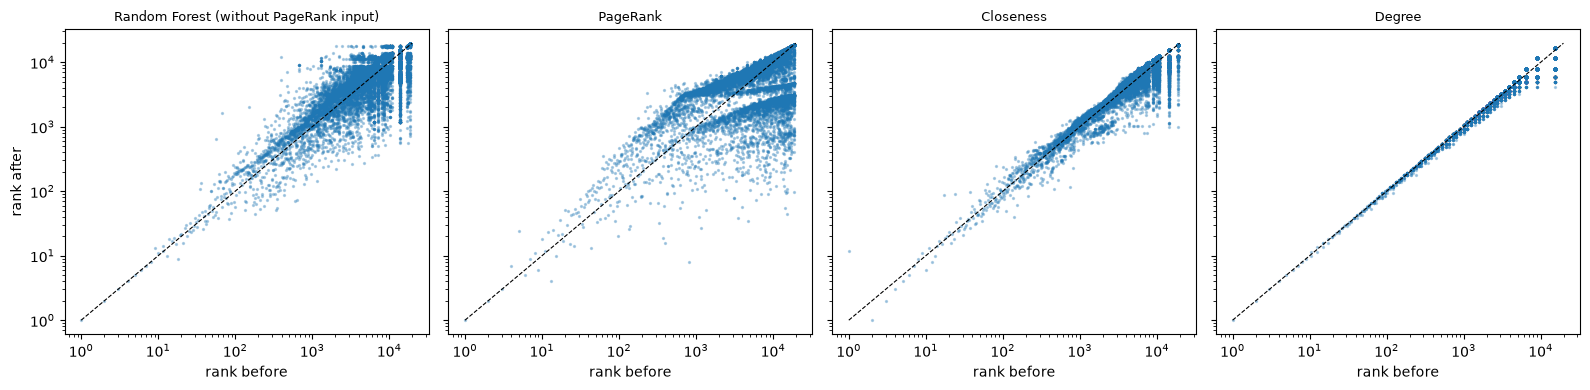

In [9]:
methods = ['rf_without_pagerank', 'pagerank', 'closeness', 'degree']
fig, axes = plt.subplots(1, len(methods), figsize=(16, 4), sharex=True, sharey=True)
for ax, m in zip(axes, methods):
    before = ranking.to_ranking(base[m])
    after = ranking.to_ranking(scores[m])
    ax.scatter(before, after, s=2, alpha=0.3)
    ax.plot([1, len(before)], [1, len(before)], 'k--', lw=0.8)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title(demo.METHOD_LABELS[m], fontsize=9); ax.set_xlabel('rank before')
axes[0].set_ylabel('rank after')
plt.tight_layout(); plt.show()

## 6. Zoom in on one paper

The paper of the forest's top 100 that lost the most places, with its direct neighbours. Grey = citation kept, red dashed = removed, green = added by the damage.

paper 15004560: rank 67 -> 1612


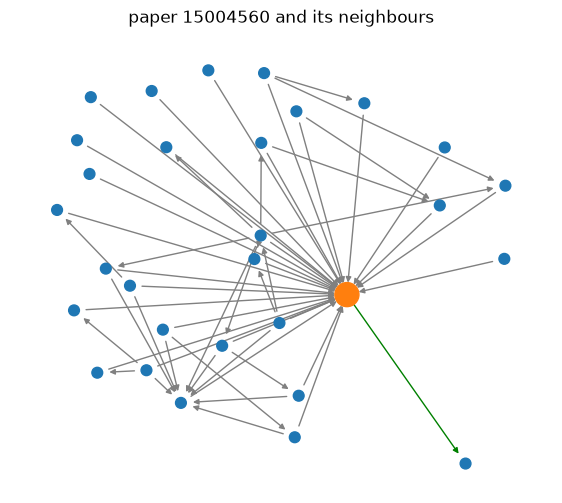

In [10]:
top100 = demo.rank_changes(base, scores, 'rf_without_pagerank', top=100)
paper = top100['moved'].idxmin()
print(f'paper {paper}: rank {top100.loc[paper, "rank before"]:.0f} -> {top100.loc[paper, "rank after"]:.0f}')

neighbours = set(g.predecessors(paper)) | set(g.successors(paper)) | set(damaged.predecessors(paper)) | set(damaged.successors(paper))
sub_nodes = [paper] + sorted(neighbours)[:40]
before_edges = {e for e in g.subgraph(sub_nodes).edges}
after_edges = {e for e in damaged.subgraph(sub_nodes).edges}

view = nx.DiGraph(); view.add_nodes_from(sub_nodes); view.add_edges_from(before_edges | after_edges)
pos = nx.spring_layout(view, seed=1)
fig, ax = plt.subplots(figsize=(7, 6))
nx.draw_networkx_nodes(view, pos, node_size=[300 if n == paper else 60 for n in view], node_color=['tab:orange' if n == paper else 'tab:blue' for n in view], ax=ax)
nx.draw_networkx_edges(view, pos, edgelist=list(before_edges & after_edges), edge_color='gray', ax=ax, arrowsize=8)
nx.draw_networkx_edges(view, pos, edgelist=list(before_edges - after_edges), edge_color='red', style='dashed', ax=ax, arrowsize=8)
nx.draw_networkx_edges(view, pos, edgelist=list(after_edges - before_edges), edge_color='green', ax=ax, arrowsize=8)
ax.set_title(f'paper {paper} and its neighbours'); ax.axis('off'); plt.show()

Why did it move? Its scaled inputs before and after the damage (what the forest sees):

In [11]:
from src import features, scaling
before = scaling.apply_scaler(scaler, features.compute_features(g)).loc[paper]
after = scaling.apply_scaler(scaler, features.compute_features(damaged)).loc[paper]
print(f'cited by {g.in_degree(paper)} -> {damaged.in_degree(paper)} papers, cites {g.out_degree(paper)} -> {damaged.out_degree(paper)} papers')
pd.DataFrame({'before': before, 'after': after}).round(4)

cited by 28 -> 28 papers, cites 0 -> 1 papers


,before,after
degree,0.1588,0.1647
betweenness,0.0000,0.0951
closeness,0.1422,0.1532
pagerank,0.1482,0.1193
kcore,0.7778,0.7778


With the default settings (add_dag, 10 %, seed 42) this is paper 15004560: cited by 28 papers, citing none, so its betweenness was 0. The damage gives it **one** new outgoing citation. Now its 28 citing papers can reach a new paper through it, so its betweenness jumps from 0 to about 0.1 (scaled). In this graph, papers that are cited a lot and cite nothing are typically older "classic" papers with high PageRank, and the forest has learned *betweenness = 0* as part of that pattern. One extra edge breaks the pattern and the forest halves the paper's score. This is the kind of fragility the stability experiment measures.

## What to take from the demo

- Every method's ranking moves when the graph is damaged; local measures (degree, k-core) move least, partly because they have few distinct values.
- Under edge **addition** the forest keeps its ranking better than PageRank, the measure it learned to imitate. Under **removal** it is a little worse.
- One damaged graph is a single example. The full experiment (30 runs per setting, notebooks 06-08) gives the reliable numbers - see `docs/results_summary.md`.